STEP 1: PATH CHECK
Original patch found
PCA model found

STEP 2: ORIGINAL PATCH
Shape: (13, 512, 512)
Minimum: 0.018808777
Maximum: 0.52628255

STEP 3: QUANTIZED COMPRESSION RESULTS
-------------------------------------------------------

Components: 5
PSNR: 42.1638 dB
SSIM: 0.991377
Compression ratio: 5.99:1
Storage reduction: 83.32%
Compressed file: /kaggle/working/pca_results/48TVN_20250725_r2_c5_K5.npz

Components: 6
PSNR: 44.6069 dB
SSIM: 0.993842
Compression ratio: 4.91:1
Storage reduction: 79.64%
Compressed file: /kaggle/working/pca_results/48TVN_20250725_r2_c5_K6.npz

Components: 8
PSNR: 47.7618 dB
SSIM: 0.997878
Compression ratio: 3.62:1
Storage reduction: 72.39%
Compressed file: /kaggle/working/pca_results/48TVN_20250725_r2_c5_K8.npz

Components: 10
PSNR: 55.5123 dB
SSIM: 0.999311
Compression ratio: 2.89:1
Storage reduction: 65.37%
Compressed file: /kaggle/working/pca_results/48TVN_20250725_r2_c5_K10.npz

STEP 4: COMPRESSED FILE VERIFICATION
File exists: True
Scores shape: (2

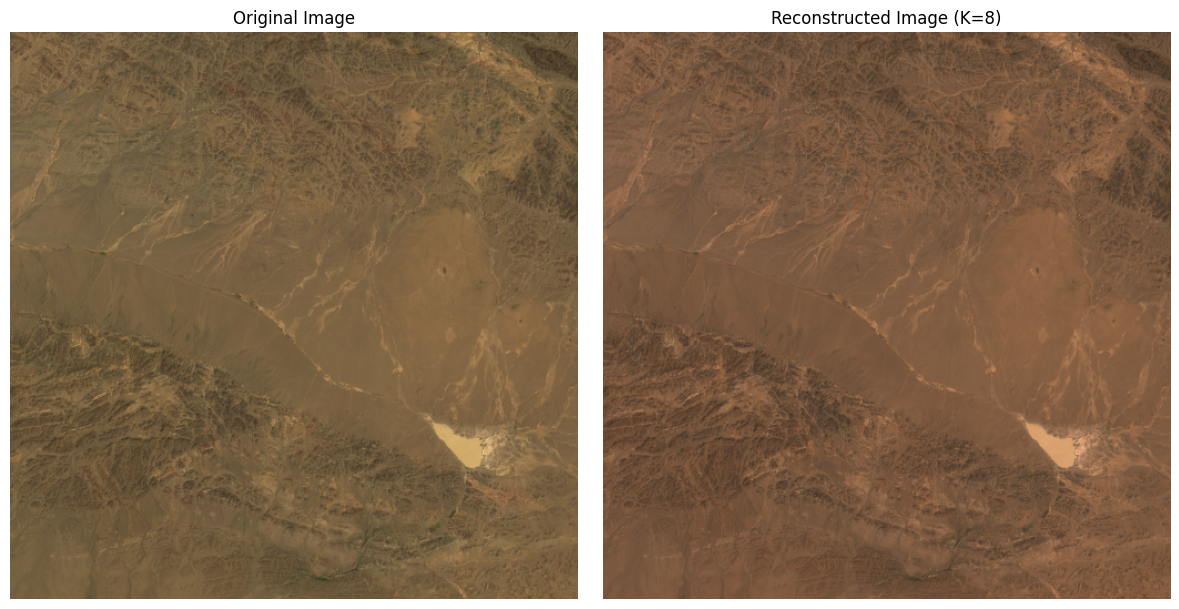


STEP 8: RECONSTRUCTION DIFFERENCE


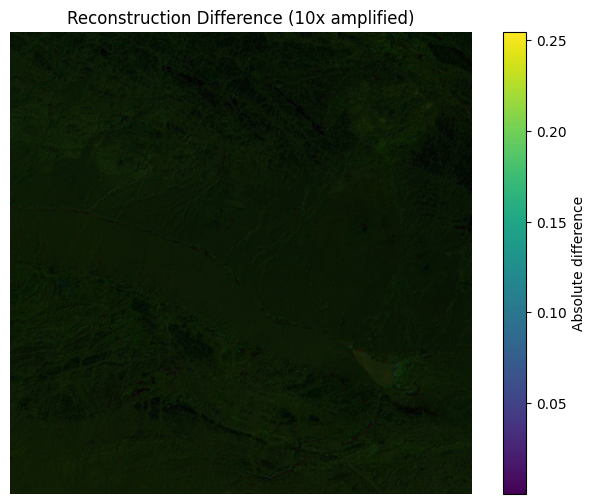


STEP 9: BAND-WISE QUALITY
B01: PSNR = 43.710 dB | SSIM = 0.992441
B02: PSNR = 52.834 dB | SSIM = 0.997513
B03: PSNR = 40.070 dB | SSIM = 0.994585
B04: PSNR = 46.430 dB | SSIM = 0.997302
B05: PSNR = 51.857 dB | SSIM = 0.997780
B06: PSNR = 50.727 dB | SSIM = 0.998120
B07: PSNR = 52.172 dB | SSIM = 0.998418
B08: PSNR = 47.276 dB | SSIM = 0.998956
B8A: PSNR = 53.105 dB | SSIM = 0.998120
B09: PSNR = 66.925 dB | SSIM = 0.999861
B10: PSNR = 75.037 dB | SSIM = 0.999968
B11: PSNR = 58.366 dB | SSIM = 0.999671
B12: PSNR = 56.224 dB | SSIM = 0.999685

STEP 10: FULL VALIDATION
Validation patches found: 165
Processed 25/165 patches
Processed 50/165 patches
Processed 75/165 patches
Processed 100/165 patches
Processed 125/165 patches
Processed 150/165 patches

========== QUANTIZED VALIDATION RESULTS ==========
Total patches: 165
Average PSNR: 47.98935414618907
Average SSIM: 0.992622022231918
Average compression ratio: 8.36221085867485
Average storage reduction: 86.94394754085229 %
Minimum PSNR: 42.8

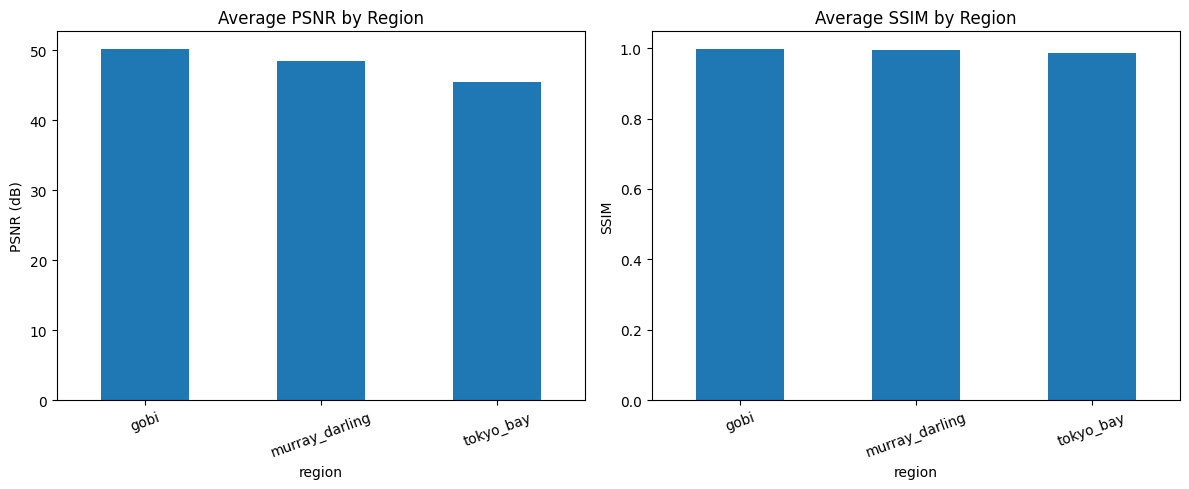

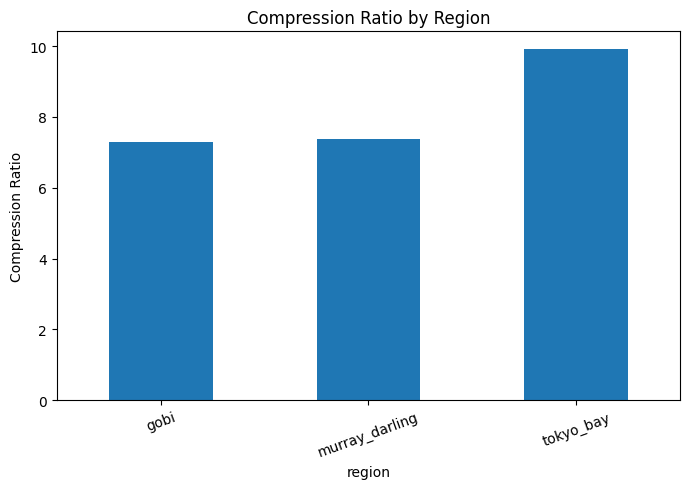

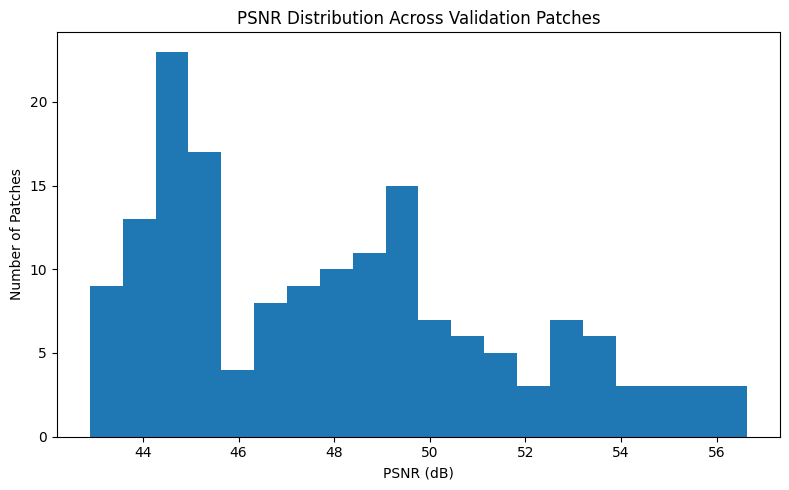


QUANTIZED PCA PIPELINE COMPLETED SUCCESSFULLY
Compressed files: /kaggle/working/pca_results
Validation CSV files: /kaggle/working/quantized_validation
Total validation patches: 165
Selected components: 8

All steps completed.


In [1]:

# ============================================================
# 03 - QUANTIZED PCA COMPRESSION AND VALIDATION
# Complete pipeline in one cell
# ============================================================

import os
import glob
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

BASE = "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval"

RESULTS = "/kaggle/working/pca_results"
OUTPUT_FOLDER = "/kaggle/working/quantized_validation"

MODEL_PATH = "/kaggle/input/notebooks/arvindreddy99920/pca-model/pca_results/pca_model.npz"

VAL_FOLDER = os.path.join(BASE, "dataset", "val")

PATCH_NAME = "48TVN_20250725_r2_c5.npy"
PATCH_PATH = os.path.join(VAL_FOLDER, "gobi", PATCH_NAME)

COMPONENT_COUNTS = [5, 6, 8, 10]
K = 8

os.makedirs(RESULTS, exist_ok=True)
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("STEP 1: PATH CHECK")

if not os.path.isfile(PATCH_PATH):
    raise FileNotFoundError(PATCH_PATH)

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(MODEL_PATH)

print("Original patch found")
print("PCA model found")


# ============================================================
# 2. LOAD PCA MODEL AND ORIGINAL PATCH
# ============================================================

model = np.load(MODEL_PATH)

mean = model["mean"].astype(np.float32)
components = model["components"].astype(np.float32)
LO = model["LO"].astype(np.float32)
HI = model["HI"].astype(np.float32)

raw = np.load(PATCH_PATH).astype(np.float32)

original = np.clip(
    raw,
    LO[:, None, None],
    HI[:, None, None]
)

original = (
    original - LO[:, None, None]
) / (
    HI - LO
)[:, None, None]

original_bytes = os.path.getsize(PATCH_PATH)

print("\nSTEP 2: ORIGINAL PATCH")
print("Shape:", original.shape)
print("Minimum:", original.min())
print("Maximum:", original.max())


# ============================================================
# 3. QUANTIZED COMPRESSION FOR K = 5, 6, 8, 10
# ============================================================

print("\nSTEP 3: QUANTIZED COMPRESSION RESULTS")
print("-" * 55)

for k in COMPONENT_COUNTS:

    selected = components[:k]

    X = original.reshape(13, -1).T
    centered = X - mean

    scores = centered @ selected.T

    score_min = scores.min(axis=0)
    score_max = scores.max(axis=0)

    score_range = np.maximum(
        score_max - score_min,
        1e-8
    )

    quantized = np.round(
        (scores - score_min) / score_range * 255
    ).clip(0, 255).astype(np.uint8)

    restored_scores = (
        quantized.astype(np.float32) / 255.0
    ) * score_range + score_min

    reconstructed_temp = (
        restored_scores @ selected + mean
    ).T.reshape(13, 512, 512)

    mse = np.mean(
        (original - reconstructed_temp) ** 2
    )

    psnr = 10.0 * np.log10(
        1.0 / max(mse, 1e-15)
    )

    ssim = np.mean([
        structural_similarity(
            original[b],
            reconstructed_temp[b],
            data_range=1.0
        )
        for b in range(13)
    ])

    output_path = os.path.join(
        RESULTS,
        f"{PATCH_NAME.replace('.npy', '')}_K{k}.npz"
    )

    np.savez_compressed(
        output_path,
        scores=quantized,
        score_min=score_min,
        score_max=score_max
    )

    compressed_bytes = os.path.getsize(output_path)

    ratio = original_bytes / compressed_bytes

    reduction = (
        1.0 - compressed_bytes / original_bytes
    ) * 100.0

    print(f"\nComponents: {k}")
    print(f"PSNR: {psnr:.4f} dB")
    print(f"SSIM: {ssim:.6f}")
    print(f"Compression ratio: {ratio:.2f}:1")
    print(f"Storage reduction: {reduction:.2f}%")
    print(f"Compressed file: {output_path}")


# ============================================================
# 4. VERIFY SAVED K=8 COMPRESSED FILE
# ============================================================

print("\nSTEP 4: COMPRESSED FILE VERIFICATION")

compressed_path = os.path.join(
    RESULTS,
    "48TVN_20250725_r2_c5_K8.npz"
)

if not os.path.isfile(compressed_path):
    raise FileNotFoundError(compressed_path)

with np.load(compressed_path) as data:

    quantized_scores = data["scores"].astype(np.float32)
    score_min = data["score_min"].astype(np.float32)
    score_max = data["score_max"].astype(np.float32)

print("File exists: True")
print("Scores shape:", quantized_scores.shape)
print("Scores dtype:", quantized_scores.dtype)


# ============================================================
# 5. RECONSTRUCT K=8 FROM SAVED QUANTIZED FILE
# ============================================================

print("\nSTEP 5: K=8 RECONSTRUCTION")

selected = components[:K]

score_range = score_max - score_min

restored_scores = (
    quantized_scores / 255.0
) * score_range + score_min

reconstructed = (
    restored_scores @ selected + mean
).T.reshape(13, 512, 512)

print("Reconstructed shape:", reconstructed.shape)
print("Minimum:", reconstructed.min())
print("Maximum:", reconstructed.max())
print("Data type:", reconstructed.dtype)


# ============================================================
# 6. PSNR AND SSIM
# ============================================================

print("\nSTEP 6: RECONSTRUCTION QUALITY")

psnr = peak_signal_noise_ratio(
    original,
    reconstructed,
    data_range=1.0
)

ssim_values = [
    structural_similarity(
        original[i],
        reconstructed[i],
        data_range=1.0
    )
    for i in range(13)
]

print("PSNR:", psnr)
print("Mean SSIM:", np.mean(ssim_values))


# ============================================================
# 7. ORIGINAL VS RECONSTRUCTED RGB IMAGES
# ============================================================

print("\nSTEP 7: IMAGE COMPARISON")

original_rgb = np.stack([
    original[3],
    original[2],
    original[1]
], axis=-1)

reconstructed_rgb = np.stack([
    reconstructed[3],
    reconstructed[2],
    reconstructed[1]
], axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(np.clip(original_rgb * 3, 0, 1))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(np.clip(reconstructed_rgb * 3, 0, 1))
axes[1].set_title("Reconstructed Image (K=8)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 8. RECONSTRUCTION DIFFERENCE
# ============================================================

print("\nSTEP 8: RECONSTRUCTION DIFFERENCE")

difference = np.abs(
    original_rgb - reconstructed_rgb
)

plt.figure(figsize=(8, 6))
plt.imshow(difference * 10)
plt.title("Reconstruction Difference (10x amplified)")
plt.colorbar(label="Absolute difference")
plt.axis("off")
plt.show()


# ============================================================
# 9. BAND-WISE RECONSTRUCTION QUALITY
# ============================================================

print("\nSTEP 9: BAND-WISE QUALITY")

band_names = [
    "B01", "B02", "B03", "B04", "B05",
    "B06", "B07", "B08", "B8A", "B09",
    "B10", "B11", "B12"
]

for i, name in enumerate(band_names):

    band_psnr = peak_signal_noise_ratio(
        original[i],
        reconstructed[i],
        data_range=1.0
    )

    band_ssim = structural_similarity(
        original[i],
        reconstructed[i],
        data_range=1.0
    )

    print(
        f"{name}: PSNR = {band_psnr:.3f} dB "
        f"| SSIM = {band_ssim:.6f}"
    )


# ============================================================
# 10. FULL QUANTIZED VALIDATION - ALL 165 PATCHES
# ============================================================

print("\nSTEP 10: FULL VALIDATION")

patch_files = sorted(
    glob.glob(
        os.path.join(VAL_FOLDER, "**", "*.npy"),
        recursive=True
    )
)

print("Validation patches found:", len(patch_files))

if len(patch_files) == 0:
    raise RuntimeError("No validation patches found.")

psnr_results = []
ssim_results = []
compression_ratios = []

for idx, path in enumerate(patch_files):

    raw_patch = np.load(path).astype(np.float32)

    original_patch = np.clip(
        raw_patch,
        LO[:, None, None],
        HI[:, None, None]
    )

    original_patch = (
        original_patch - LO[:, None, None]
    ) / (
        HI - LO
    )[:, None, None]

    pixels = original_patch.reshape(13, -1).T

    scores = (
        pixels - mean
    ) @ selected.T

    score_min = scores.min(axis=0)
    score_max = scores.max(axis=0)

    score_range = np.maximum(
        score_max - score_min,
        1e-8
    )

    quantized = np.round(
        (scores - score_min) / score_range * 255
    ).clip(0, 255).astype(np.uint8)

    scores_float = (
        quantized.astype(np.float32) / 255.0
    ) * score_range + score_min

    reconstructed_patch = (
        scores_float @ selected + mean
    ).T.reshape(13, 512, 512)

    patch_psnr = peak_signal_noise_ratio(
        original_patch,
        reconstructed_patch,
        data_range=1.0
    )

    band_ssim = [
        structural_similarity(
            original_patch[b],
            reconstructed_patch[b],
            data_range=1.0
        )
        for b in range(13)
    ]

    buffer = io.BytesIO()

    np.savez_compressed(
        buffer,
        scores=quantized,
        score_min=score_min,
        score_max=score_max
    )

    compressed_size = len(buffer.getvalue())

    original_size = raw_patch.nbytes

    ratio = original_size / compressed_size

    psnr_results.append(patch_psnr)
    ssim_results.append(np.mean(band_ssim))
    compression_ratios.append(ratio)

    if (idx + 1) % 25 == 0:
        print(
            f"Processed {idx + 1}/{len(patch_files)} patches"
        )


# ============================================================
# 11. OVERALL VALIDATION RESULTS
# ============================================================

print("\n========== QUANTIZED VALIDATION RESULTS ==========")

print("Total patches:", len(psnr_results))
print("Average PSNR:", np.mean(psnr_results))
print("Average SSIM:", np.mean(ssim_results))
print("Average compression ratio:", np.mean(compression_ratios))

print(
    "Average storage reduction:",
    (
        1 - np.mean(1 / np.array(compression_ratios))
    ) * 100,
    "%"
)

print("Minimum PSNR:", np.min(psnr_results))
print("Minimum SSIM:", np.min(ssim_results))


# ============================================================
# 12. PATCH-WISE AND REGION-WISE RESULTS
# ============================================================

results_df = pd.DataFrame({
    "patch": [os.path.basename(p) for p in patch_files],
    "region": [
        os.path.basename(os.path.dirname(p))
        for p in patch_files
    ],
    "PSNR": psnr_results,
    "SSIM": ssim_results,
    "Compression_Ratio": compression_ratios
})

region_summary = results_df.groupby("region").agg(
    Patch_Count=("patch", "count"),
    Mean_PSNR=("PSNR", "mean"),
    Mean_SSIM=("SSIM", "mean"),
    Min_PSNR=("PSNR", "min"),
    Min_SSIM=("SSIM", "min"),
    Mean_Compression_Ratio=("Compression_Ratio", "mean")
).round(4)

print("\nREGION-WISE RESULTS")
print(region_summary)


# ============================================================
# 13. WORST 10 PATCHES
# ============================================================

print("\n10 WORST PATCHES BY PSNR")

print(
    results_df.sort_values("PSNR").head(10).to_string(index=False)
)

print("\n10 WORST PATCHES BY SSIM")

print(
    results_df.sort_values("SSIM").head(10).to_string(index=False)
)


# ============================================================
# 14. SAVE ALL CSV RESULTS
# ============================================================

print("\nSTEP 14: SAVING CSV FILES")

results_df.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "quantized_validation_details.csv"
    ),
    index=False
)

region_summary.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "quantized_region_summary.csv"
    )
)

overall_summary = pd.DataFrame([{
    "Components": K,
    "Total_Patches": len(results_df),
    "Average_PSNR": results_df["PSNR"].mean(),
    "Average_SSIM": results_df["SSIM"].mean(),
    "Average_Compression_Ratio": results_df["Compression_Ratio"].mean(),
    "Average_Storage_Reduction_Per_Patch": (
        1 - (1 / results_df["Compression_Ratio"])
    ).mean() * 100
}])

overall_summary.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "quantized_overall_summary.csv"
    ),
    index=False
)

print("CSV files saved successfully:")
print(os.listdir(OUTPUT_FOLDER))


# ============================================================
# 15. REGION-WISE PSNR AND SSIM GRAPHS
# ============================================================

print("\nSTEP 15: GENERATING GRAPHS")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

region_summary["Mean_PSNR"].plot(
    kind="bar",
    ax=axes[0],
    title="Average PSNR by Region"
)

axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=20)

region_summary["Mean_SSIM"].plot(
    kind="bar",
    ax=axes[1],
    title="Average SSIM by Region"
)

axes[1].set_ylabel("SSIM")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


# ============================================================
# 16. COMPRESSION RATIO GRAPH
# ============================================================

region_summary["Mean_Compression_Ratio"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Compression Ratio by Region"
)

plt.ylabel("Compression Ratio")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ============================================================
# 17. PSNR DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(results_df["PSNR"], bins=20)

plt.xlabel("PSNR (dB)")
plt.ylabel("Number of Patches")
plt.title("PSNR Distribution Across Validation Patches")

plt.tight_layout()
plt.show()


# ============================================================
# 18. FINAL STATUS
# ============================================================

print("\n" + "=" * 55)
print("QUANTIZED PCA PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 55)

print("Compressed files:", RESULTS)
print("Validation CSV files:", OUTPUT_FOLDER)
print("Total validation patches:", len(results_df))
print("Selected components:", K)

print("\nAll steps completed.")
